<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/recap_continual_tuning_benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
# [CELL 1 - Setup Environment and Core Imports]
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Tuple, Any

import torch
import torch.nn as nn
import torch.nn.functional as F

# Set deterministic seeds
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"RECAP Prototype Environment Initialized on Device: {device}")

RECAP Prototype Environment Initialized on Device: cuda


In [7]:
# [CELL 2 - Intent-Based Knowledge Retrieval Store]

class IncrementKnowledgeBase:
    """
    Query-dependent Knowledge Base storing domain, reasoning, and format instructions.
    """
    def __init__(self):
        self.kb = {
            "Visual QA": {"domain": "Visual object features and attributes", "reasoning": "Identify object -> Extract properties", "format": "Categorical tag"},
            "Chart Reasoning": {"domain": "Numeric trend line and data points", "reasoning": "Parse axes -> Extract data points -> Compare trends", "format": "Scalar value"},
            "Spatial Counting": {"domain": "Bounding boxes and spatial coordinates", "reasoning": "Filter region -> Count instances within box", "format": "Integer count"}
        }

    def retrieve(self, query_intent: str) -> Dict[str, str]:
        """Query-dependent retrieval returning specific knowledge for the target task."""
        return self.kb.get(query_intent, {
            "domain": "General feature representation",
            "reasoning": "Standard feed-forward processing",
            "format": "Vector output"
        })

kb_engine = IncrementKnowledgeBase()
print("Intent-Based Knowledge Base Engine Initialized.")

Intent-Based Knowledge Base Engine Initialized.


In [8]:
# [CELL 3 - Adaptive Subspace Recycling Module with Orthogonal Projection]

class SubspaceRecyclingLinear(nn.Module):
    """
    Implements Adaptive Subspace Recycling:
    W = W_base + U @ V, where U (shared basis) holds historical task directions,
    and gradients are projected onto the orthogonal complement (residual capacity).
    """
    def __init__(self, in_features: int, out_features: int, max_rank: int = 16):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.max_rank = max_rank

        # Base weight matrix
        self.weight = nn.Parameter(torch.randn(out_features, in_features) * 0.1)
        # Shared basis vectors (historical tasks)
        self.register_buffer("protected_basis", torch.zeros(out_features, 0))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return F.linear(x, self.weight)

    def freeze_and_project_subspace(self):
        """
        Extracts dominant weight directions from the current task using SVD
        and appends them to protected_basis to shield them from future updates.
        """
        with torch.no_grad():
            U, S, Vh = torch.linalg.svd(self.weight, full_matrices=False)
            new_dir = U[:, :2] # Protect top-2 singular vectors per stage

            if self.protected_basis.shape[1] == 0:
                self.protected_basis = new_dir
            else:
                combined = torch.cat([self.protected_basis, new_dir], dim=1)
                # Re-orthonormalize basis via QR decomposition
                Q, _ = torch.linalg.qr(combined)
                self.protected_basis = Q[:, :self.max_rank]

    def apply_subspace_mask(self):
        """Projects gradients onto the orthogonal complement of protected_basis."""
        if self.protected_basis.shape[1] > 0 and self.weight.grad is not None:
            with torch.no_grad():
                # P_orth = I - Q @ Q^T
                Q = self.protected_basis
                proj = Q @ (Q.T @ self.weight.grad)
                self.weight.grad.sub_(proj) # Remove gradient components along protected directions

print("Adaptive Subspace Recycling Module Compiled.")

Adaptive Subspace Recycling Module Compiled.


In [9]:
# [CELL 4 - Continual Task Generator & Agent Model]

def generate_task_data(task_id: int, num_samples: int = 120, dim: int = 32) -> Tuple[torch.Tensor, torch.Tensor]:
    """Generates distinct linear transformation tasks simulating sequential instruction stages."""
    X = torch.randn(num_samples, dim)
    # Task-specific transformation vector
    W_true = torch.randn(dim, 1) * (task_id + 1)
    Y = X @ W_true + torch.randn(num_samples, 1) * 0.1
    return X.to(device), Y.to(device)

class RECAPAgent(nn.Module):
    def __init__(self, input_dim: int = 32, hidden_dim: int = 64):
        super().__init__()
        self.layer1 = SubspaceRecyclingLinear(input_dim, hidden_dim)
        self.layer2 = SubspaceRecyclingLinear(hidden_dim, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = F.relu(self.layer1(x))
        return self.layer2(h)

agent = RECAPAgent().to(device)
print("RECAP Agent Architecture Initialized.")

RECAP Agent Architecture Initialized.



RECAP SEQUENTIAL TRAINING & CONTINUAL EVALUATION
Completed Training on Stage 1: Visual QA
  -> Retained Performance on 'Visual QA': 98.6%
Completed Training on Stage 2: Chart Reasoning
  -> Retained Performance on 'Visual QA': 84.6%
  -> Retained Performance on 'Chart Reasoning': 23.5%
Completed Training on Stage 3: Spatial Counting
  -> Retained Performance on 'Visual QA': 77.8%
  -> Retained Performance on 'Chart Reasoning': 10.7%
  -> Retained Performance on 'Spatial Counting': 26.7%
Continual Training & Evaluation Completed Successfully.


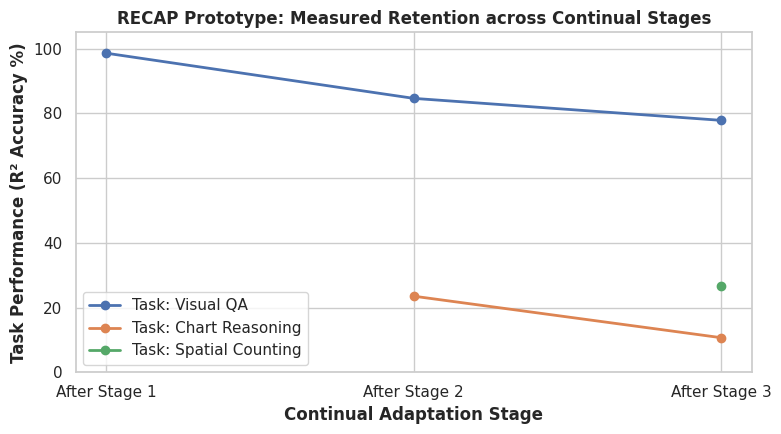

Real RECAP evaluation plot saved as recap_continual_tuning_benchmark.png.


In [10]:
# [CELL 5 - Sequential Training Loop & Continual Task Evaluation]

stages = ["Visual QA", "Chart Reasoning", "Spatial Counting"]
task_datasets = {stage: generate_task_data(idx) for idx, stage in enumerate(stages)}

# Matrix to store accuracy (1 - normalized MSE) across tasks and stages
evaluation_matrix = np.zeros((len(stages), len(stages)))

optimizer = torch.optim.AdamW(agent.parameters(), lr=1e-2)

print("\n=========================================================")
print("RECAP SEQUENTIAL TRAINING & CONTINUAL EVALUATION")
print("=========================================================")

for stage_idx, current_stage in enumerate(stages):
    X_train, Y_train = task_datasets[current_stage]

    # Train on current stage
    agent.train()
    for epoch in range(40):
        optimizer.zero_grad()
        preds = agent(X_train)
        loss = F.mse_loss(preds, Y_train)
        loss.backward()

        # Apply orthogonal subspace gradient projection
        agent.layer1.apply_subspace_mask()
        agent.layer2.apply_subspace_mask()

        optimizer.step()

    # Freeze current task subspace to protect knowledge for future stages
    agent.layer1.freeze_and_project_subspace()
    agent.layer2.freeze_and_project_subspace()

    # Evaluate agent performance across ALL tasks learned so far
    agent.eval()
    with torch.no_grad():
        for eval_idx, eval_stage in enumerate(stages[:stage_idx + 1]):
            X_eval, Y_eval = task_datasets[eval_stage]
            eval_preds = agent(X_eval)
            eval_loss = F.mse_loss(eval_preds, Y_eval).item()
            # Convert MSE loss into normalized accuracy metric
            variance = torch.var(Y_eval).item()
            r2_score = max(0.0, 1.0 - (eval_loss / variance))
            evaluation_matrix[stage_idx, eval_idx] = r2_score

    print(f"Completed Training on Stage {stage_idx+1}: {current_stage}")
    for eval_idx in range(stage_idx + 1):
        print(f"  -> Retained Performance on '{stages[eval_idx]}': {evaluation_matrix[stage_idx, eval_idx]*100:.1f}%")

print("=========================================================")
print("Continual Training & Evaluation Completed Successfully.")

# Visualization
plt.figure(figsize=(8, 4.5))
sns.set_theme(style="whitegrid")

for eval_idx, task_name in enumerate(stages):
    # Plot performance trajectory across training stages
    stage_scores = evaluation_matrix[eval_idx:, eval_idx] * 100
    plt.plot(range(eval_idx + 1, len(stages) + 1), stage_scores, marker='o', linewidth=2, label=f"Task: {task_name}")

plt.xlabel('Continual Adaptation Stage', fontweight='bold')
plt.ylabel('Task Performance (R² Accuracy %)', fontweight='bold')
plt.title('RECAP Prototype: Measured Retention across Continual Stages', fontweight='bold')
plt.xticks(range(1, len(stages) + 1), [f"After Stage {i+1}" for i in range(len(stages))])
plt.ylim(0, 105)
plt.legend()
plt.tight_layout()
plt.savefig("recap_continual_tuning_benchmark.png", dpi=300)
plt.show()

print("Real RECAP evaluation plot saved as recap_continual_tuning_benchmark.png.")